# 02 — Phân tích Random Forest (mô hình chính)

Notebook này **hiển thị** kết quả của `python -m src.rf_analysis` (không tính lại), để mọi số liệu
khớp với `reports/results_snapshot.md` §9. Nếu chưa có kết quả, ô bên dưới sẽ tự chạy bản nhanh.

Nội dung:
1. Validation curve theo `n_estimators` và `max_depth` — tham số đã tune nằm ở đâu trên đường bias–variance.
2. OOB vs cross-validation vs test.
3. Độ quan trọng đặc trưng theo 3 cách: MDI, permutation, SHAP — và mức đồng thuận giữa chúng.
4. Giải thích cục bộ (SHAP) cho 3 khách hàng: TP, FN, FP.

**Đổi `DATASET`** sang dataset chính sau khi chốt D1 (`'ibm'` hoặc `'iranian'`).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
from IPython.display import Image, display

DATASET = 'ibm'   # 'ibm' | 'iranian' | 'orange'
RESULTS = ROOT / 'results' / 'rf_analysis'
FIGURES = ROOT / 'figures' / 'rf'

if not (RESULTS / f'{DATASET}_importance.csv').exists():
    import os
    os.chdir(ROOT)
    from src.rf_analysis import analyse_dataset, OUT_DIR, FIG_DIR
    OUT_DIR.mkdir(parents=True, exist_ok=True); FIG_DIR.mkdir(parents=True, exist_ok=True)
    analyse_dataset(DATASET, quick=True)

pd.set_option('display.max_colwidth', 80)

## 1. Validation curve

Trục tung là average precision (AP) trên cross-validation của **tập train**. Khoảng cách giữa đường
Train và đường CV thể hiện mức overfit; đường CV đi ngang nghĩa là tăng tham số không còn lợi.
Đường nét đứt là giá trị đã chọn khi tune.

,param,value,train_mean,train_std,cv_mean,cv_std
0,n_estimators,50.0,0.7908,0.0067,0.6568,0.0259
1,n_estimators,100.0,0.7936,0.0058,0.6608,0.0244
2,n_estimators,200.0,0.7948,0.0055,0.6629,0.0254
3,n_estimators,300.0,0.7956,0.0058,0.6641,0.0254
4,n_estimators,500.0,0.7959,0.0051,0.6641,0.0251
5,max_depth,3.0,0.6538,0.0049,0.6430,0.0221
6,max_depth,5.0,0.6847,0.0058,0.6575,0.0222
7,max_depth,8.0,0.7522,0.0061,0.6659,0.0241
8,max_depth,12.0,0.8209,0.0047,0.6614,0.0259
9,max_depth,NaN,0.8347,0.0031,0.6610,0.0273


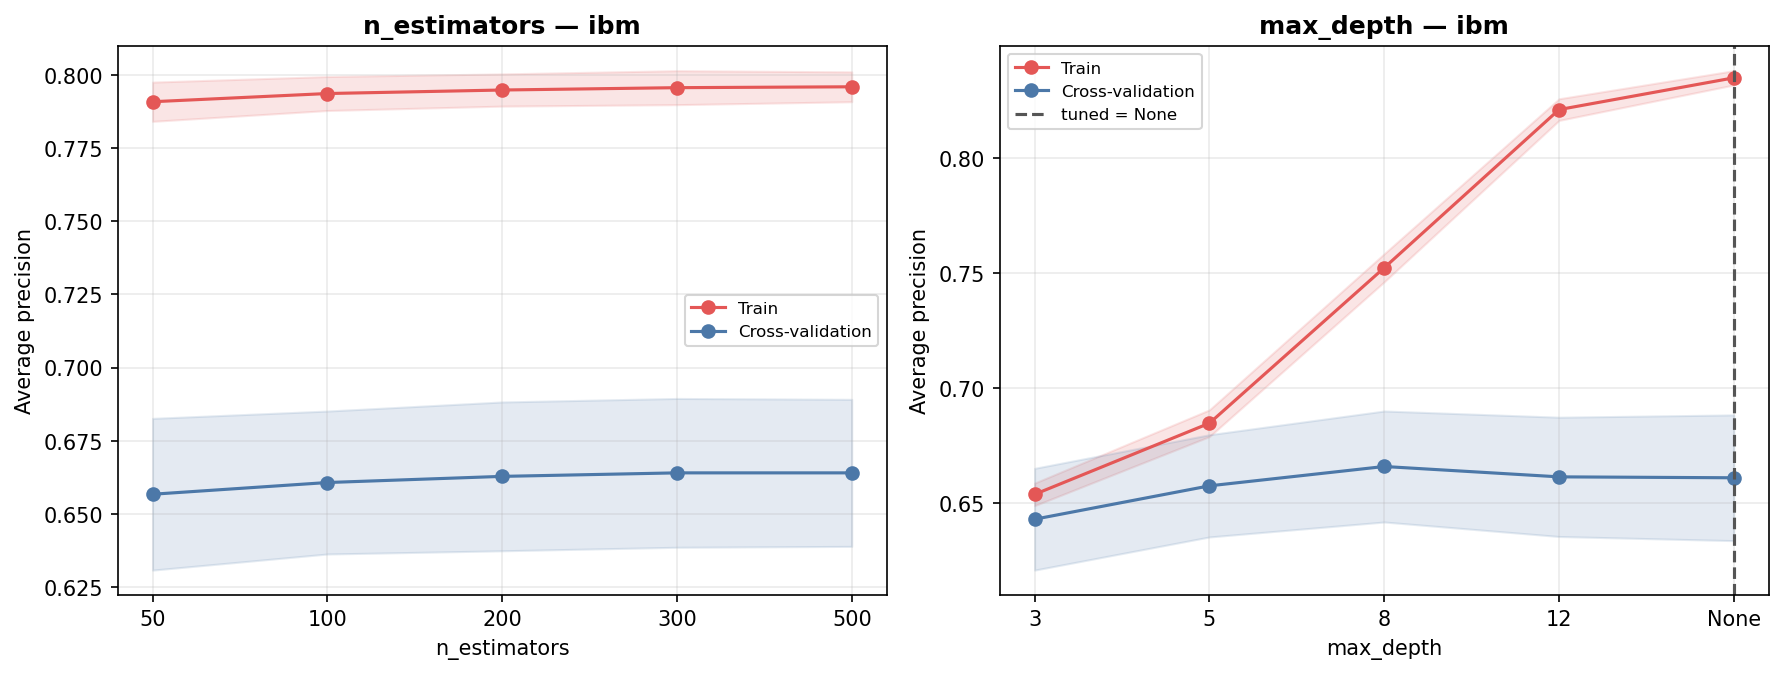

In [2]:
display(pd.read_csv(RESULTS / f'{DATASET}_validation_curve.csv'))
display(Image(filename=str(FIGURES / f'validation_curve_{DATASET}.png')))

## 2. OOB vs CV vs test

OOB (out-of-bag) là ước lượng "miễn phí" của RF: mỗi cây được đánh giá trên các dòng không nằm
trong mẫu bootstrap của nó. Nếu OOB ≈ CV ≈ test thì đánh giá đáng tin. Với Iranian, OOB có thể
lạc quan vì một bản trùng có thể nằm trong mẫu bootstrap trong khi bản kia là OOB.

In [3]:
summary = pd.read_csv(RESULTS / 'rf_summary.csv')
display(summary[summary['dataset'] == DATASET].T)

,0
dataset,ibm
n_estimators,500
max_depth,10.0
oob_ap,0.6615
oob_roc_auc,0.8458
cv_ap_mean,0.6641
cv_ap_std,0.0251
test_ap,0.6603
test_roc_auc,0.8506
spearman_mdi_permutation,0.845


## 3. Độ quan trọng đặc trưng — 3 cách

- **MDI**: tổng mức giảm impurity; nhanh nhưng thiên vị biến có nhiều giá trị và tính trên tập train.
- **Permutation**: AP trên test giảm bao nhiêu khi xáo trộn một cột gốc; phản ánh đúng hiệu năng,
  nhưng chia điểm giữa các biến tương quan (có thể âm).
- **SHAP**: đóng góp trung bình |SHAP| của từng biến vào xác suất dự đoán.

Hệ số Spearman (ρ) trong bảng ở mục 2 cho biết các cách xếp hạng có đồng thuận không.

,feature,mdi,permutation,shap,mdi_rank,permutation_rank,shap_rank
0,charges_per_tenure,0.20474,NaN,0.07344,1.0,NaN,1.0
1,Contract,0.10766,0.04697,0.06684,3.0,2.0,2.0
2,tenure,0.13970,0.16284,0.05595,2.0,1.0,3.0
3,InternetService,0.07089,0.02977,0.05467,4.0,3.0,4.0
4,is_high_risk_contract,0.06303,NaN,0.03644,6.0,NaN,5.0
5,security_support_services,0.03580,NaN,0.02549,8.0,NaN,6.0
6,PaymentMethod,0.04945,0.00742,0.02412,7.0,8.0,7.0
7,TechSupport,0.03227,0.01756,0.02238,10.0,5.0,8.0
8,OnlineSecurity,0.03285,0.01569,0.02229,9.0,6.0,9.0
9,MonthlyCharges,0.07035,0.02597,0.02018,5.0,4.0,10.0


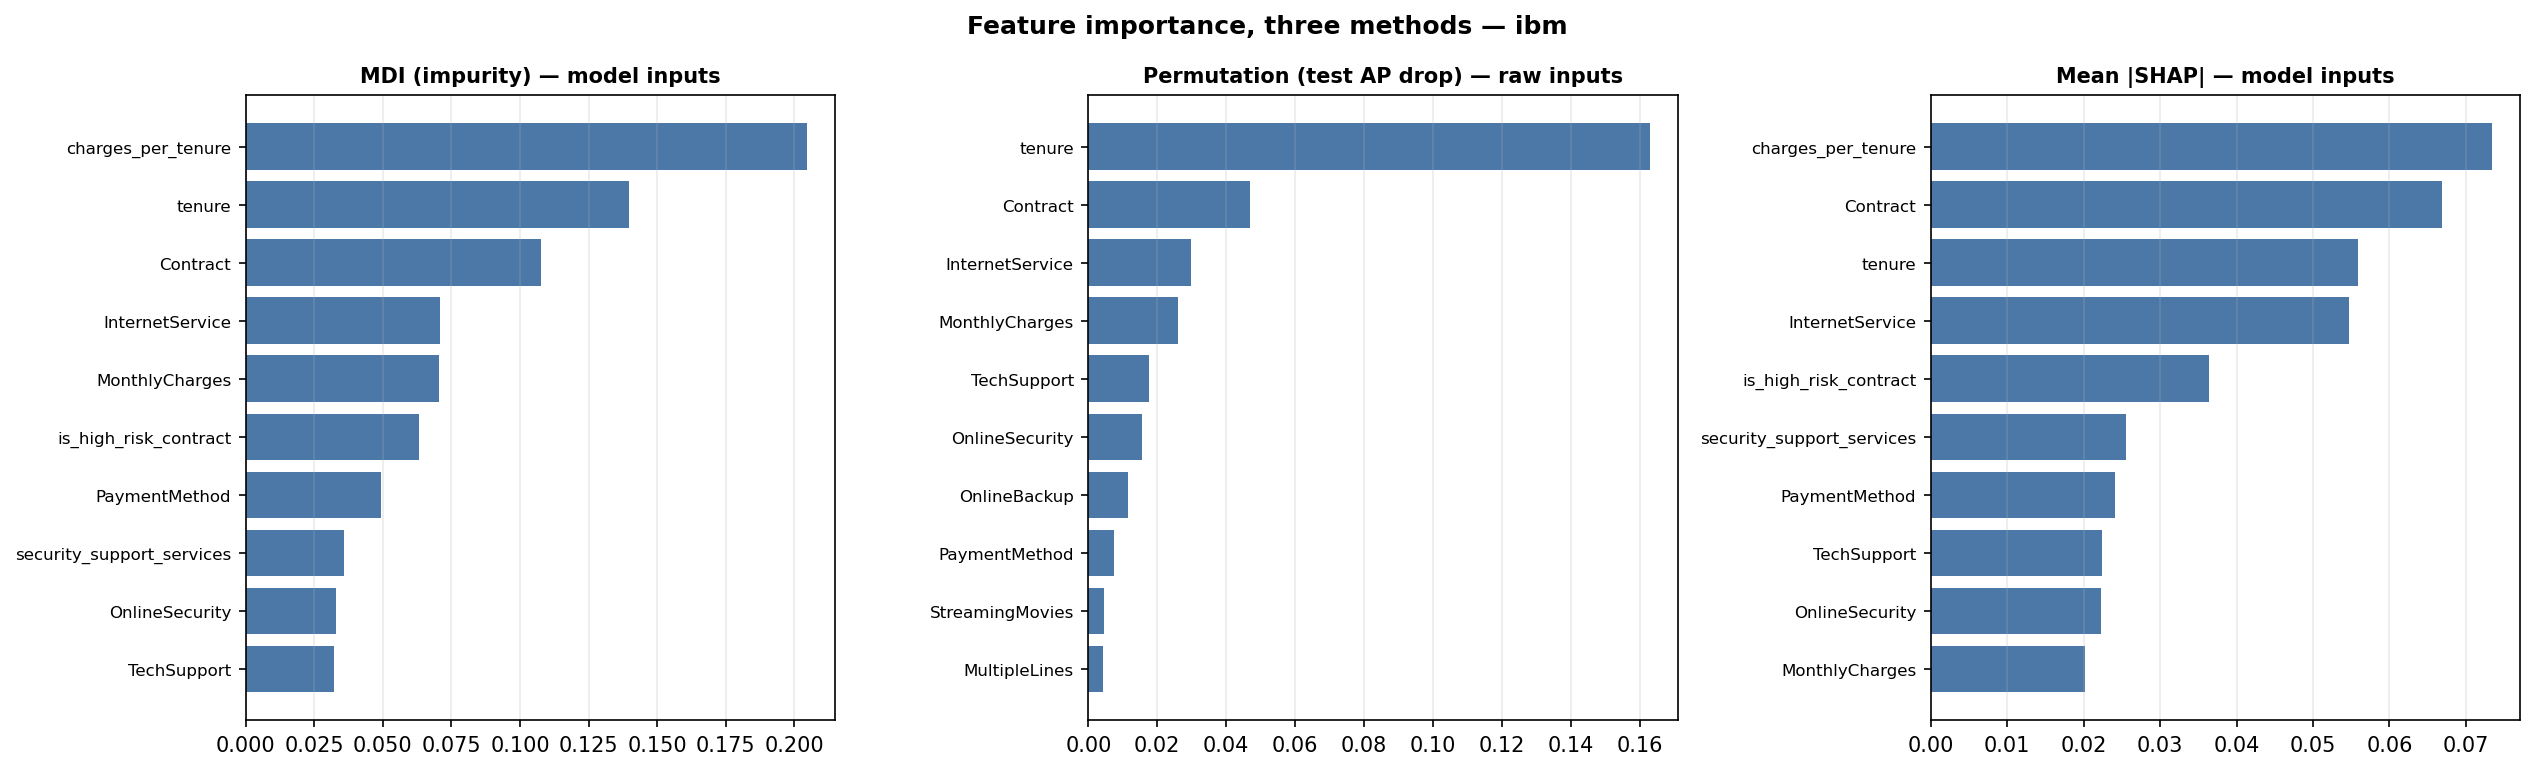

In [4]:
importance = pd.read_csv(RESULTS / f'{DATASET}_importance.csv')
display(importance.head(12))
display(Image(filename=str(FIGURES / f'importance_methods_{DATASET}.png')))

## 4. Giải thích cục bộ — vì sao mô hình đúng/sai với từng khách

Thanh đỏ đẩy xác suất churn **lên**, thanh xanh kéo **xuống**. FN (bỏ sót) và FP (báo nhầm) là
chất liệu tốt cho phần thảo luận hạn chế của mô hình. Đây là tương quan mà mô hình học được,
**không phải quan hệ nhân quả**.

,case,churn_probability,actual_churn,rank,feature,value,contribution
0,TP (most confident churner caught),0.9398,1,1,charges_per_tenure,38.225,0.1055
1,TP (most confident churner caught),0.9398,1,2,tenure,1,0.0777
2,TP (most confident churner caught),0.9398,1,3,InternetService,Fiber optic,0.0473
3,TP (most confident churner caught),0.9398,1,4,is_high_risk_contract,1,0.0428
4,TP (most confident churner caught),0.9398,1,5,Contract,Month-to-month,0.0382
5,TP (most confident churner caught),0.9398,1,6,PaymentMethod,Electronic check,0.0233
6,FN (churner most clearly missed),0.0841,1,1,charges_per_tenure,1.2316326530612245,-0.1096
7,FN (churner most clearly missed),0.0841,1,2,tenure,48,-0.0638
8,FN (churner most clearly missed),0.0841,1,3,InternetService,DSL,-0.0428
9,FN (churner most clearly missed),0.0841,1,4,security_support_services,2,-0.0357


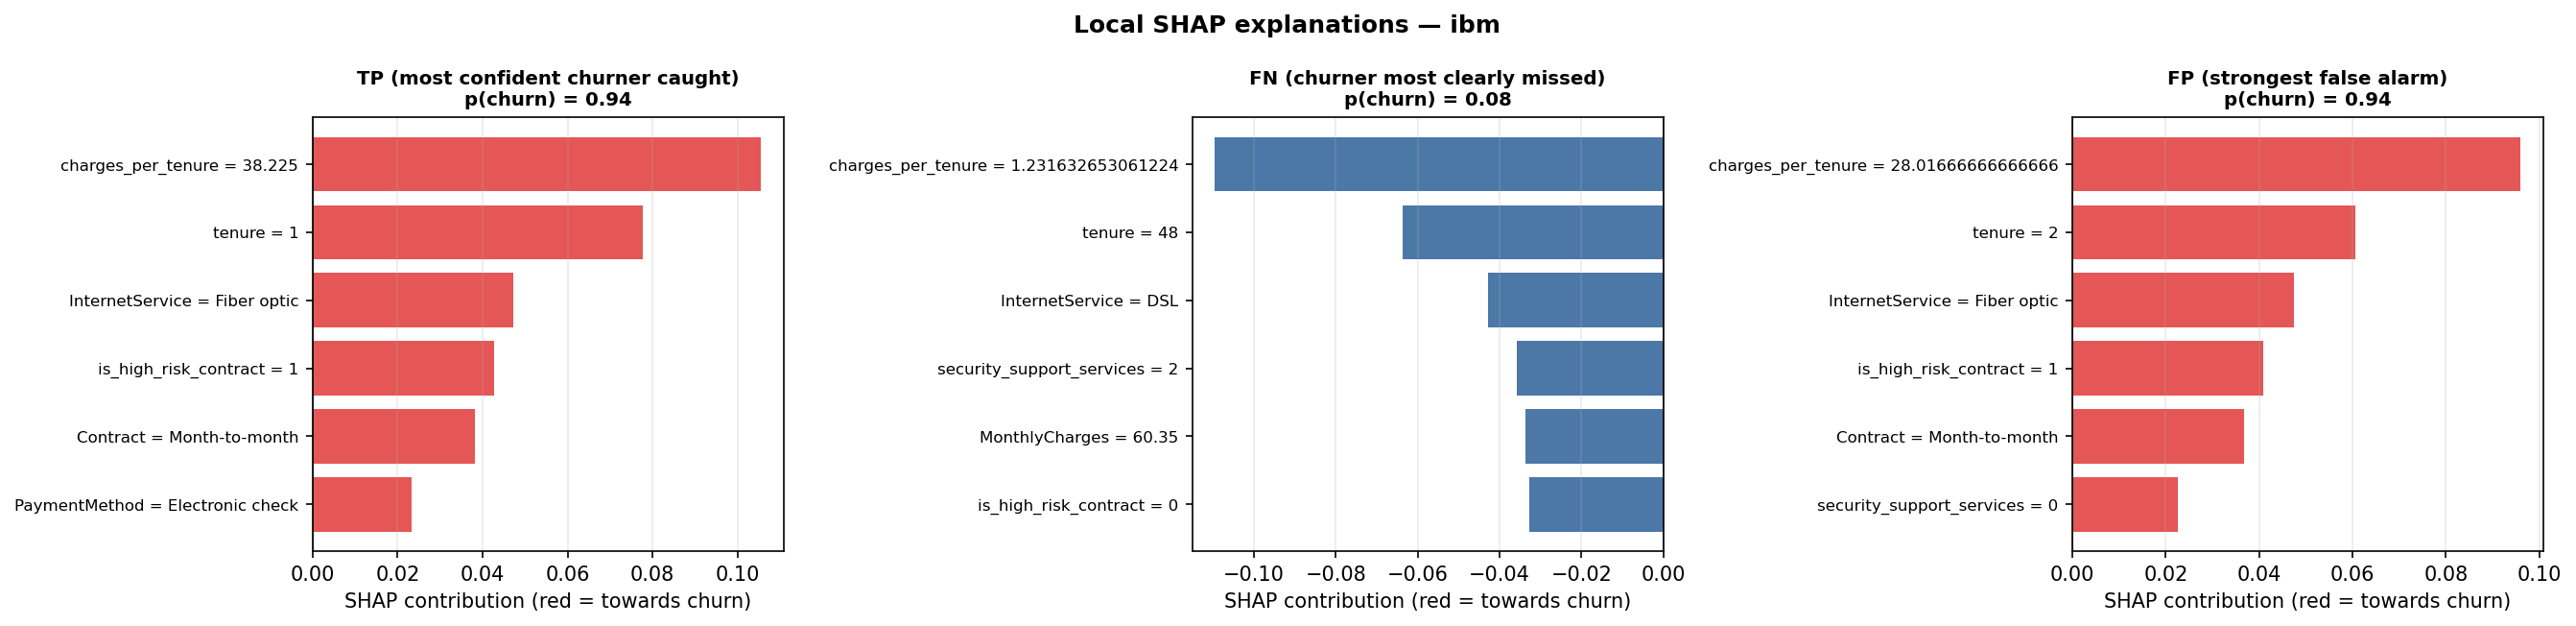

In [5]:
local = pd.read_csv(RESULTS / f'{DATASET}_local_shap.csv')
display(local[['case', 'churn_probability', 'actual_churn', 'rank', 'feature', 'value', 'contribution']])
display(Image(filename=str(FIGURES / f'local_shap_{DATASET}.png')))

## 5. Calibration (bổ sung)

Reliability diagram của các cách calibrate (từ `python -m src.calibration_analysis`), dùng cho
mục 5.2 và cho Nhật Linh ở mục 5.3.

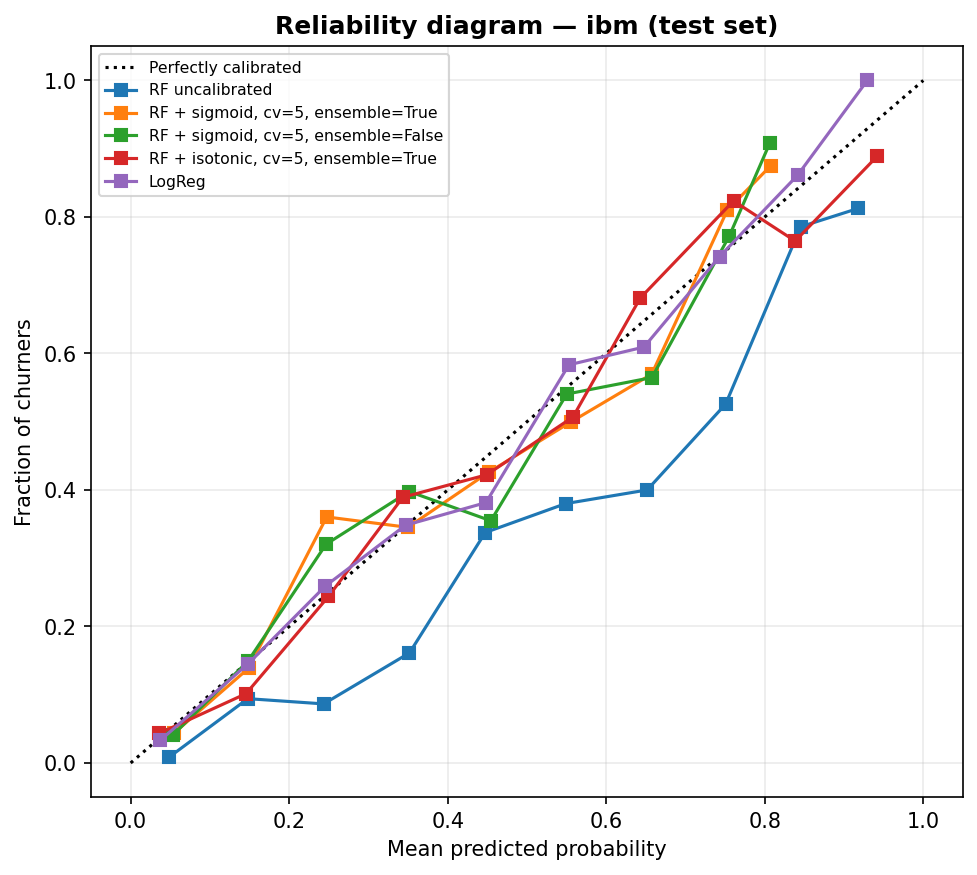

,dataset,model,deployed,roc_auc,average_precision,brier_score,log_loss,ece,fit_seconds,size_mb,size_mb_compressed
0,ibm,RF uncalibrated,False,0.8506,0.6603,0.1526,0.4586,0.1213,2.32,16.97,6.67
1,ibm,"RF + sigmoid, cv=5, ensemble=True",False,0.8519,0.6626,0.1345,0.4135,0.0322,10.06,73.97,28.63
2,ibm,"RF + sigmoid, cv=5, ensemble=False",True,0.8506,0.6603,0.1352,0.4148,0.0309,6.86,16.94,6.64
3,ibm,"RF + isotonic, cv=5, ensemble=True",False,0.8517,0.6625,0.1332,0.4093,0.0269,4.73,73.98,28.63
4,ibm,LogReg,False,0.8527,0.6723,0.1330,0.4050,0.0155,0.28,0.01,0.00


In [6]:
path = FIGURES / f'reliability_{DATASET}.png'
if path.exists():
    display(Image(filename=str(path)))
    display(pd.read_csv(ROOT / 'results' / 'calibration' / 'calibration_comparison.csv'))
else:
    print('Chưa có: chạy python -m src.calibration_analysis --dataset', DATASET)